# Bike Sharing Demand Prediction Using Machine Learning

## Project Overview

This project develops a machine learning system to predict bike-sharing demand using historical rental, weather, seasonal, and time-related information.

The project includes data preprocessing, exploratory data analysis, feature engineering, multiple machine learning models, model evaluation, and demand prediction.

## Methodology

The project follows these steps:

1. Load the Bike Sharing Dataset.
2. Inspect and clean the data.
3. Perform exploratory data analysis.
4. Create useful date-based features.
5. Separate input features and the target variable.
6. Split the data chronologically into training and testing sets.
7. Train Linear Regression, Random Forest Regression, and Gradient Boosting Regression models.
8. Evaluate the models using MAE, RMSE, and R².
9. Select the model with the lowest RMSE.
10. Generate bike demand predictions using the selected model.

## Dataset Description

The dataset contains historical bike-sharing rental information along with temporal, weather, and environmental variables.

The target variable is:

- `cnt` — total number of bike rentals.

The `casual` and `registered` variables were excluded from model training because they directly contribute to the target variable:

`cnt = casual + registered`

Removing these variables prevents target leakage and provides a more realistic prediction setup.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Setup successful!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Setup successful!
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1


In [2]:
import pandas as pd
import gzip
import base64
from io import BytesIO

# Embedded Bike Sharing Dataset
embedded_dataset = """..."""

# Decode and load dataset
compressed_data = base64.b64decode(embedded_dataset)
csv_data = gzip.decompress(compressed_data)

df = pd.read_csv(BytesIO(csv_data))

print("Dataset loaded successfully from embedded data.")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully from embedded data.
Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 17379
Number of columns: 17


In [4]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [5]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [6]:
# Statistical summary

df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [7]:
# Create a working copy of the dataset

data = df.copy()

# Convert date column to datetime format
data["dteday"] = pd.to_datetime(data["dteday"])

# Display data types
data.dtypes

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

In [8]:
# Check for duplicate rows

duplicates = data.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [9]:
# Check the target variable

print("Target variable: cnt")
print("Minimum rentals:", data["cnt"].min())
print("Maximum rentals:", data["cnt"].max())
print("Average rentals:", round(data["cnt"].mean(), 2))

Target variable: cnt
Minimum rentals: 1
Maximum rentals: 977
Average rentals: 189.46


In [10]:
# Feature engineering from the date

data["year"] = data["dteday"].dt.year
data["month"] = data["dteday"].dt.month
data["day"] = data["dteday"].dt.day

# Display the new features
data[["dteday", "year", "month", "day"]].head()

,dteday,year,month,day
0,2011-01-01,2011,1,1
1,2011-01-01,2011,1,1
2,2011-01-01,2011,1,1
3,2011-01-01,2011,1,1
4,2011-01-01,2011,1,1


In [11]:
# Remove columns that could cause data leakage

data = data.drop(columns=["casual", "registered"])

print("Remaining columns:")
print(data.columns.tolist())

Remaining columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'year', 'month', 'day']


In [12]:
# Final dataset check

print("Dataset shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

Dataset shape: (17379, 18)
Missing values: 0
Duplicate rows: 0


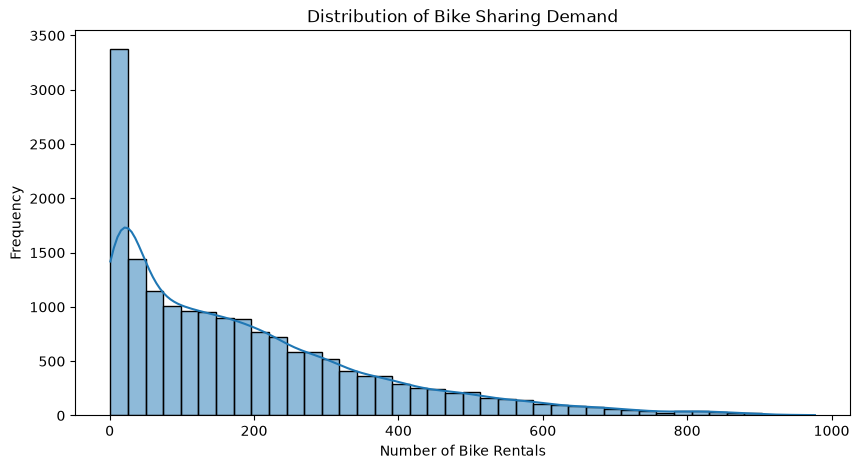

In [13]:
# Distribution of total bike rentals

plt.figure(figsize=(10, 5))
sns.histplot(data["cnt"], bins=40, kde=True)
plt.title("Distribution of Bike Sharing Demand")
plt.xlabel("Number of Bike Rentals")
plt.ylabel("Frequency")
plt.show()

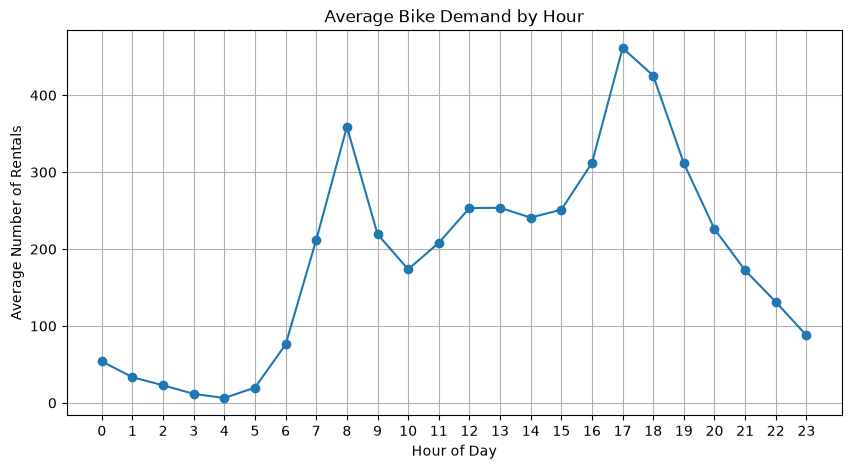

In [14]:
# Average bike demand by hour

hourly_demand = data.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")
plt.title("Average Bike Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

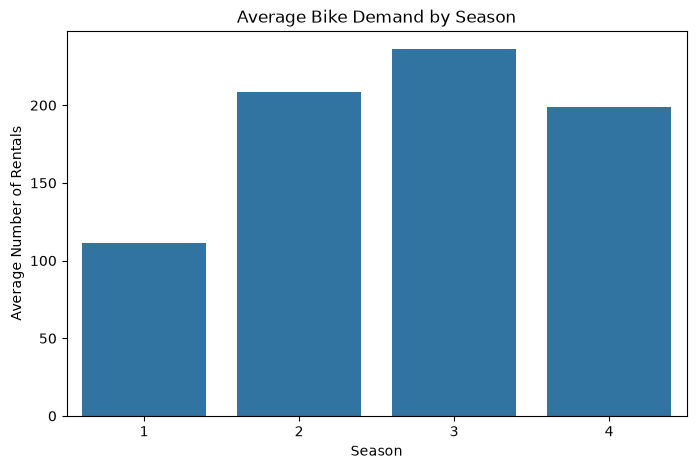

In [15]:
# Average bike demand by season

season_demand = data.groupby("season")["cnt"].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=season_demand.index, y=season_demand.values)
plt.title("Average Bike Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Number of Rentals")
plt.show()

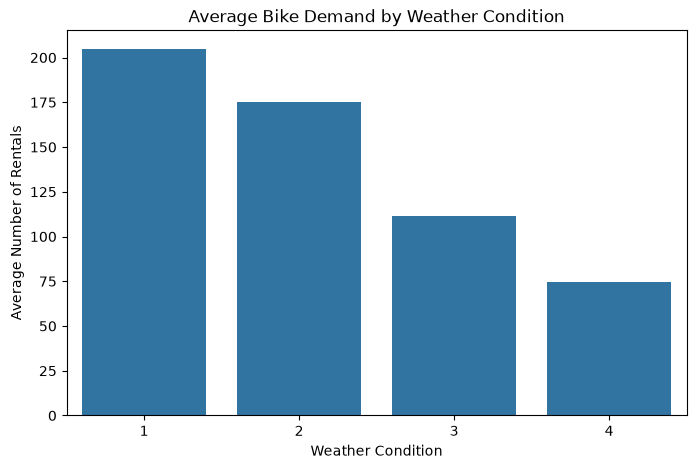

In [16]:
# Average bike demand by weather condition

weather_demand = data.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=weather_demand.index, y=weather_demand.values)
plt.title("Average Bike Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Number of Rentals")
plt.show()

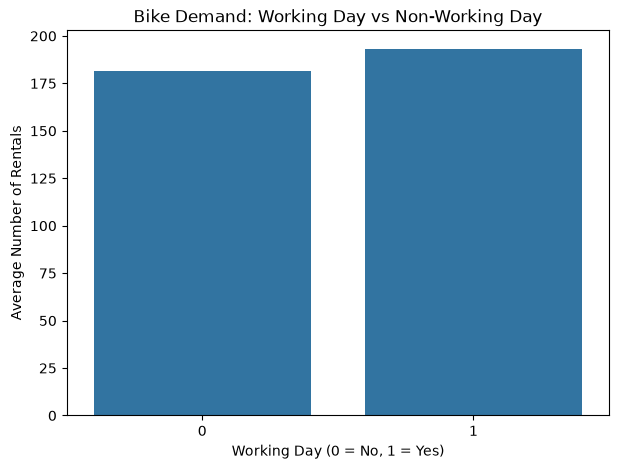

In [17]:
# Average demand on working and non-working days

workingday_demand = data.groupby("workingday")["cnt"].mean()

plt.figure(figsize=(7, 5))
sns.barplot(x=workingday_demand.index, y=workingday_demand.values)
plt.title("Bike Demand: Working Day vs Non-Working Day")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Rentals")
plt.show()

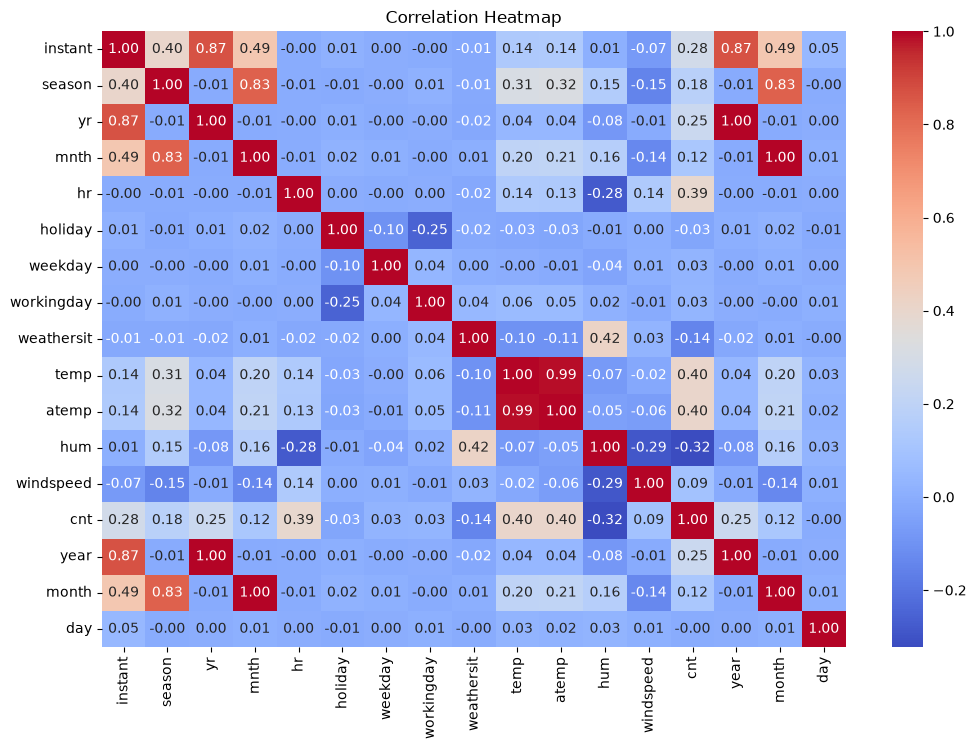

In [18]:
# Correlation between numerical variables

plt.figure(figsize=(12, 8))

correlation = data.select_dtypes(include="number").corr()

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [19]:
# Define features and target variable

X = data.drop(columns=["cnt", "dteday"])
y = data["cnt"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (17379, 16)
Target shape: (17379,)


In [20]:
# Time-based train-test split

split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 13903
Testing samples: 3476


In [21]:
# Verify the training and testing periods

print("Training period:")
print(data["dteday"].iloc[0], "to", data["dteday"].iloc[split_index - 1])

print("\nTesting period:")
print(data["dteday"].iloc[split_index], "to", data["dteday"].iloc[-1])

Training period:
2011-01-01 00:00:00 to 2012-08-07 00:00:00

Testing period:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Training data shape: (13903, 16)
Testing data shape: (3476, 16)


In [23]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [24]:
# Make predictions on the test data

y_pred_linear = linear_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("First 10 predictions:")
print(y_pred_linear[:10])

Predictions generated successfully!
First 10 predictions:
[324.43414024 335.60068706 351.74967134 349.23907458 324.69639259
 344.05065337 344.41190629 346.06964432 339.60539617 334.14127995]


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", round(mae_linear, 2))
print("RMSE:", round(rmse_linear, 2))
print("R²   :", round(r2_linear, 4))

Linear Regression Results
-------------------------
MAE : 137.89
RMSE: 183.81
R²   : 0.305


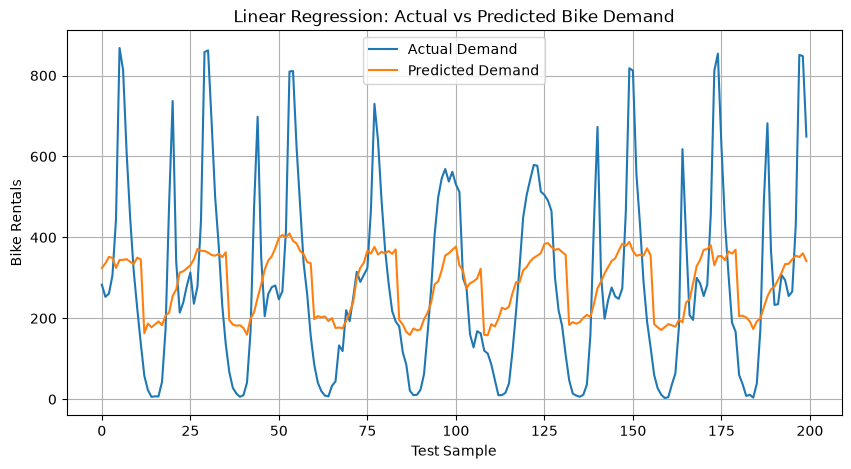

In [26]:
# Compare actual and predicted demand

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.values[:200],
    label="Actual Demand"
)

plt.plot(
    y_pred_linear[:200],
    label="Predicted Demand"
)

plt.title("Linear Regression: Actual vs Predicted Bike Demand")
plt.xlabel("Test Sample")
plt.ylabel("Bike Rentals")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created.")

Random Forest model created.


In [28]:
# Train Random Forest

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [29]:
# Generate predictions

y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("First 10 predictions:")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!
First 10 predictions:
[265.72305497 264.82677483 280.24818786 279.97708111 358.63583333
 779.06929605 785.97105597 578.59083095 425.49124026 277.7037149 ]


In [30]:
# Evaluate Random Forest

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE :", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R²   :", round(r2_rf, 4))

Random Forest Results
---------------------
MAE : 49.66
RMSE: 80.69
R²   : 0.8661


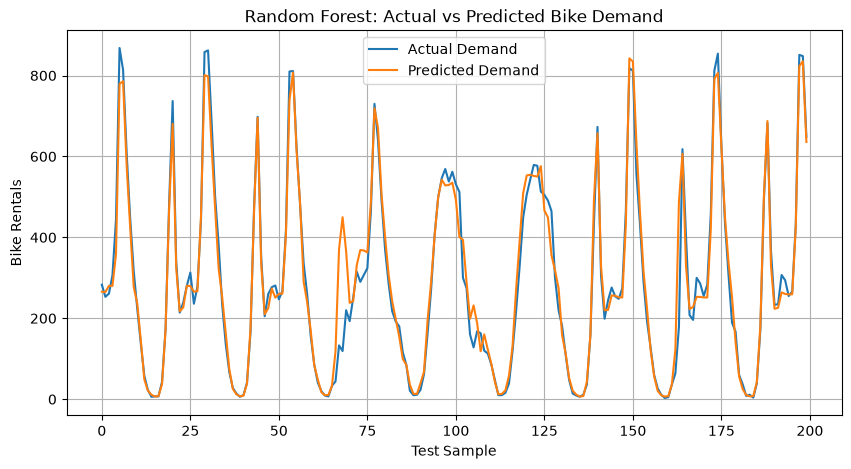

In [31]:
# Actual vs predicted demand

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.values[:200],
    label="Actual Demand"
)

plt.plot(
    y_pred_rf[:200],
    label="Predicted Demand"
)

plt.title("Random Forest: Actual vs Predicted Bike Demand")
plt.xlabel("Test Sample")
plt.ylabel("Bike Rentals")
plt.legend()
plt.grid(True)
plt.show()

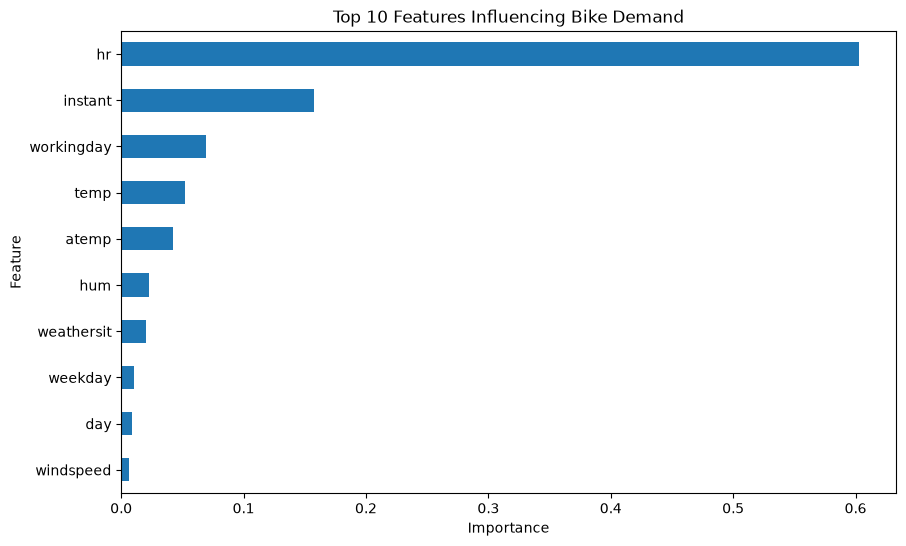

In [32]:
# Feature importance

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Features Influencing Bike Demand")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [33]:
from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

print("Gradient Boosting model created.")

Gradient Boosting model created.


In [34]:
# Train Gradient Boosting

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [35]:
# Generate predictions

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting predictions generated successfully!")

Gradient Boosting predictions generated successfully!


In [36]:
# Evaluate Gradient Boosting

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE :", round(mae_gb, 2))
print("RMSE:", round(rmse_gb, 2))
print("R²   :", round(r2_gb, 4))

Gradient Boosting Results
-------------------------
MAE : 58.27
RMSE: 88.1
R²   : 0.8404


In [37]:
# Compare all trained models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_linear,
        r2_rf,
        r2_gb
    ]
})

model_comparison = model_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

model_comparison

,Model,MAE,RMSE,R2 Score
0,Random Forest,49.657094,80.688261,0.866074
1,Gradient Boosting,58.272548,88.096584,0.840353
2,Linear Regression,137.894067,183.808247,0.305020


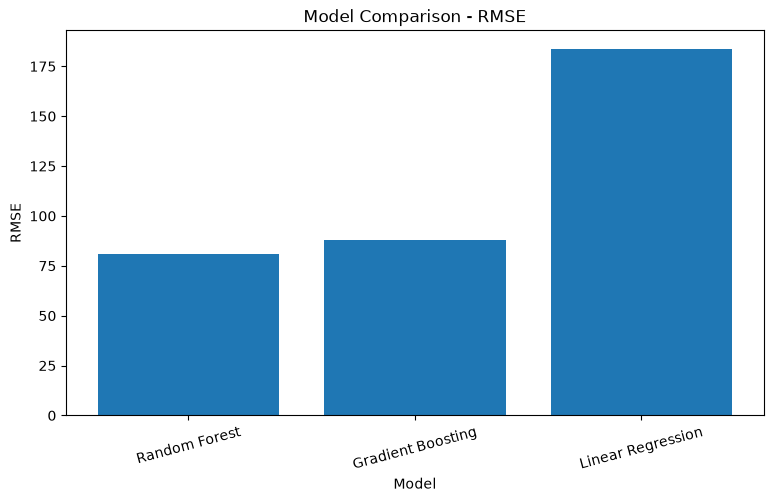

In [38]:
# Compare RMSE values

plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.show()

In [39]:
# Select the best model based on lowest RMSE

best_model_name = model_comparison.loc[
    model_comparison["RMSE"].idxmin(), "Model"
]

print("Best-performing model based on RMSE:", best_model_name)

Best-performing model based on RMSE: Random Forest


In [40]:
# Get predictions from the selected model

if best_model_name == "Linear Regression":
    best_predictions = y_pred_linear
    best_model = linear_model

elif best_model_name == "Random Forest":
    best_predictions = y_pred_rf
    best_model = rf_model

else:
    best_predictions = y_pred_gb
    best_model = gb_model

print("Final model selected:", best_model_name)

Final model selected: Random Forest


In [41]:
# Final evaluation of the selected model

final_mae = mean_absolute_error(y_test, best_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, best_predictions))
final_r2 = r2_score(y_test, best_predictions)

print("FINAL MODEL PERFORMANCE")
print("=======================")
print("Model:", best_model_name)
print("MAE :", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))
print("R²  :", round(final_r2, 4))

FINAL MODEL PERFORMANCE
Model: Random Forest
MAE : 49.66
RMSE: 80.69
R²  : 0.8661


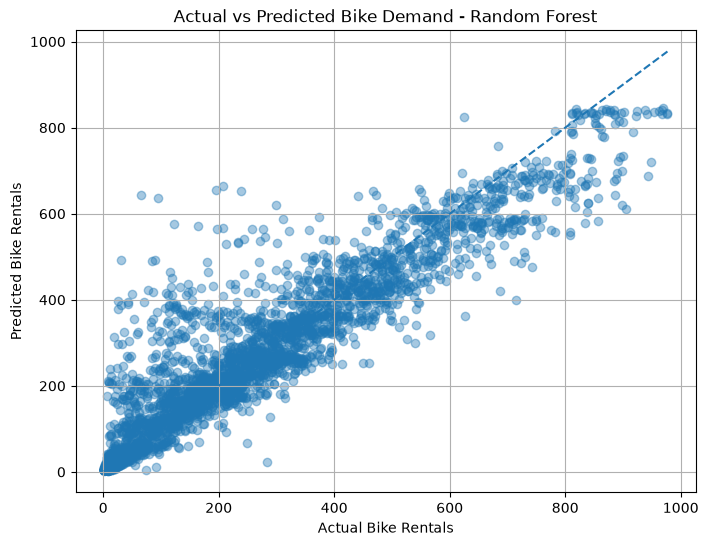

In [42]:
# Actual vs predicted values

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.4
)

# Reference line
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Bike Demand - {best_model_name}")
plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.grid(True)
plt.show()

In [43]:
# Final model results

final_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Value": [final_mae, final_rmse, final_r2]
})

final_results

,Metric,Value
0,MAE,49.657094
1,RMSE,80.688261
2,R² Score,0.866074


## Final Model Results

The trained models were evaluated using:

- **MAE (Mean Absolute Error):** Measures the average absolute prediction error.
- **RMSE (Root Mean Squared Error):** Gives greater weight to larger prediction errors.
- **R² Score:** Measures the proportion of target variation explained by the model.

The final model was selected based on the lowest RMSE on the test dataset.

In [44]:
# Select one example from the test dataset

sample_index = 0

sample_features = X_test.iloc[[sample_index]]
actual_demand = y_test.iloc[sample_index]

print("Sample input:")
display(sample_features)

print("\nActual bike demand:", actual_demand)

Sample input:


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,year,month,day
13903,13904,3,1,8,12,0,2,1,2,0.8,0.7576,0.55,0.1343,2012,8,7



Actual bike demand: 283


In [45]:
if best_model_name == "Linear Regression":
    sample_prediction = best_model.predict(
        scaler.transform(sample_features)
    )[0]
else:
    sample_prediction = best_model.predict(sample_features)[0]

In [46]:
# Calculate prediction error

prediction_error = abs(actual_demand - sample_prediction)

print("Absolute prediction error:", round(prediction_error, 2))

Absolute prediction error: 17.28


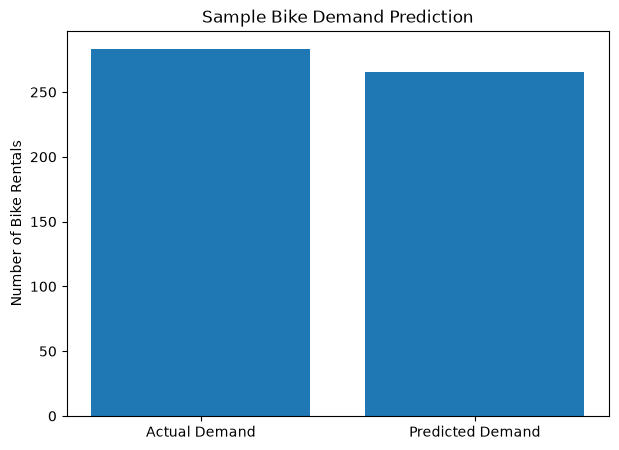

In [47]:
# Visualize actual vs predicted demand

plt.figure(figsize=(7, 5))

plt.bar(
    ["Actual Demand", "Predicted Demand"],
    [actual_demand, sample_prediction]
)

plt.title("Sample Bike Demand Prediction")
plt.ylabel("Number of Bike Rentals")
plt.show()

In [48]:
# Compare predictions for 10 test samples

sample_actual = y_test.iloc[:10].values
sample_predicted = best_predictions[:10]

prediction_comparison = pd.DataFrame({
    "Actual Demand": sample_actual,
    "Predicted Demand": np.round(sample_predicted, 2),
    "Absolute Error": np.round(
        np.abs(sample_actual - sample_predicted), 2
    )
})

prediction_comparison

,Actual Demand,Predicted Demand,Absolute Error
0,283,265.72,17.28
1,253,264.83,11.83
2,261,280.25,19.25
3,306,279.98,26.02
4,445,358.64,86.36
5,868,779.07,88.93
6,814,785.97,28.03
7,610,578.59,31.41
8,448,425.49,22.51
9,317,277.70,39.30


# Conclusion

This project successfully developed a machine learning pipeline for predicting bike-sharing demand.

The dataset was cleaned and analyzed to understand the relationship between bike rentals and factors such as time, season, weather, temperature, humidity, and windspeed.

Three regression algorithms were trained and evaluated:

- Linear Regression
- Random Forest Regression
- Gradient Boosting Regression

The models were compared using MAE, RMSE, and R² score. The final model was selected based on its test-set performance and was subsequently used to generate bike-demand predictions.

The project demonstrates how historical bike-sharing data can be used to build a machine learning-based demand prediction system.

## Technologies Used

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Machine Learning Techniques

- Linear Regression
- Random Forest Regression
- Gradient Boosting Regression

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score